# Getting start with CLIMADA

In [6]:
import numpy as np
from climada.hazard import TCTracks
import warnings  # To hide the warnings

warnings.filterwarnings("ignore")

tracks = TCTracks.from_ibtracs_netcdf(
    provider="usa", basin="NA"
) 

2026-10-13 13:57:02,880 - climada.hazard.tc_tracks - WARNING - 1012 storm events are discarded because no valid wind/pressure values have been found: 1851175N26270, 1851181N19275, 1851187N22262, 1851192N12300, 1851214N14321, ...
2026-10-13 13:57:02,887 - climada.hazard.tc_tracks - WARNING - 142 storm events are discarded because only one valid timestep has been found: 1852232N21293, 1853242N12336, 1855236N12304, 1856221N25277, 1856235N13302, ...


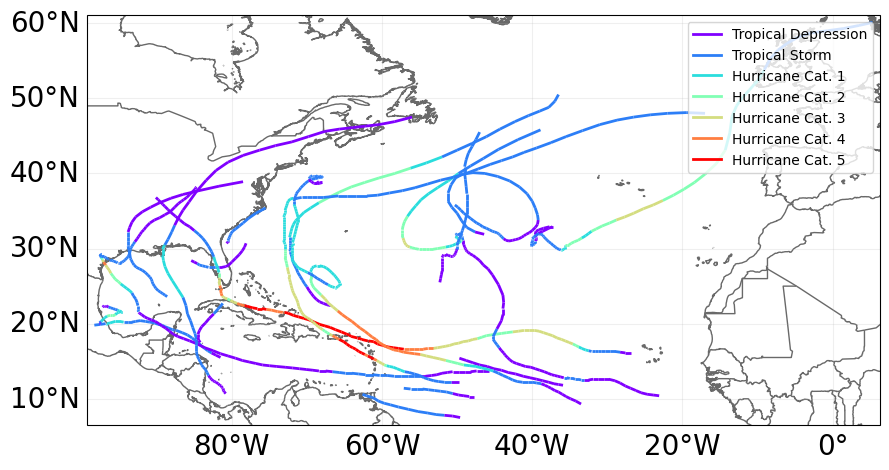

In [7]:
# plotting tracks can be very time consuming, depending on the number of tracks. So we choose only a few here, by limiting the time range to one year
tracks_2017 = TCTracks.from_ibtracs_netcdf(
    provider="usa", basin="NA", year_range=(2017, 2017)
)
tracks_2017.plot();  # This may take a very long time

## River flood

In [9]:
import inspect
from climada_petals.hazard import river_flood
print(river_flood.__file__)

/Users/mig/s/envs/climada_env/lib/python3.12/site-packages/climada_petals/hazard/river_flood.py


In [16]:
import numpy as np
import matplotlib.pyplot as plt
from climada_petals.hazard.river_flood import RiverFlood
from climada.hazard.centroids import Centroids
from climada_petals.util.constants import HAZ_DEMO_FLDDPH, HAZ_DEMO_FLDFRC
import pandas as pd

print(HAZ_DEMO_FLDDPH, HAZ_DEMO_FLDFRC)

import xarray as xr
print(xr.open_dataset(HAZ_DEMO_FLDDPH))
print(xr.open_dataset(HAZ_DEMO_FLDFRC))

/Users/mig/climada/demo/data/flddph_2000_DEMO.nc /Users/mig/climada/demo/data/fldfrc_2000_DEMO.nc
<xarray.Dataset> Size: 231kB
Dimensions:  (time: 1, lon: 230, lat: 247)
Coordinates:
  * time     (time) datetime64[ns] 8B 2000-07-02T12:00:00
  * lon      (lon) float64 2kB 5.729 5.771 5.812 5.854 ... 15.19 15.23 15.27
  * lat      (lat) float64 2kB 55.77 55.73 55.69 55.65 ... 45.6 45.56 45.52
Data variables:
    flddph   (time, lat, lon) float32 227kB ...
Attributes:
    CDI:          Climate Data Interface version ?? (http://mpimet.mpg.de/cdi)
    history:      Mon Nov 16 10:12:00 2020: cdo -k grid sellonlatbox,5.7,15.3...
    Conventions:  CF-1.4
    CDO:          Climate Data Operators version 1.9.3 (http://mpimet.mpg.de/...
<xarray.Dataset> Size: 231kB
Dimensions:  (time: 1, lon: 230, lat: 247)
Coordinates:
  * time     (time) datetime64[ns] 8B 2000-07-02T12:00:00
  * lon      (lon) float64 2kB 5.729 5.771 5.812 5.854 ... 15.19 15.23 15.27
  * lat      (lat) float64 2kB 55.77 55.73 5

In [17]:
with xr.open_dataset(HAZ_DEMO_FLDDPH) as ds:
    print(ds)
    print(pd.to_datetime(ds["time"].values).year.unique())

<xarray.Dataset> Size: 231kB
Dimensions:  (time: 1, lon: 230, lat: 247)
Coordinates:
  * time     (time) datetime64[ns] 8B 2000-07-02T12:00:00
  * lon      (lon) float64 2kB 5.729 5.771 5.812 5.854 ... 15.19 15.23 15.27
  * lat      (lat) float64 2kB 55.77 55.73 55.69 55.65 ... 45.6 45.56 45.52
Data variables:
    flddph   (time, lat, lon) float32 227kB ...
Attributes:
    CDI:          Climate Data Interface version ?? (http://mpimet.mpg.de/cdi)
    history:      Mon Nov 16 10:12:00 2020: cdo -k grid sellonlatbox,5.7,15.3...
    Conventions:  CF-1.4
    CDO:          Climate Data Operators version 1.9.3 (http://mpimet.mpg.de/...
Index([2000], dtype='int32')


In [21]:
with xr.open_dataset(HAZ_DEMO_FLDDPH) as ds:
    print(ds.coords)
    print(ds.lon.min().values, ds.lon.max().values)
    print(ds.lat.min().values, ds.lat.max().values)

Coordinates:
  * time     (time) datetime64[ns] 8B 2000-07-02T12:00:00
  * lon      (lon) float64 2kB 5.729 5.771 5.812 5.854 ... 15.19 15.23 15.27
  * lat      (lat) float64 2kB 55.77 55.73 55.69 55.65 ... 45.6 45.56 45.52
5.729166666666657 15.270833333333314
45.520833333333336 55.770833333333336


In [42]:
years = [2000]
# generating RiverFlood hazard from netCDF file
# uses centroids from Natural Earth Multipolygon for Germany
rf = RiverFlood.from_isimip_nc(countries = ['DEU'], years=years, dph_path=HAZ_DEMO_FLDDPH, frc_path=HAZ_DEMO_FLDFRC)

resolution: 0.0416666666666643


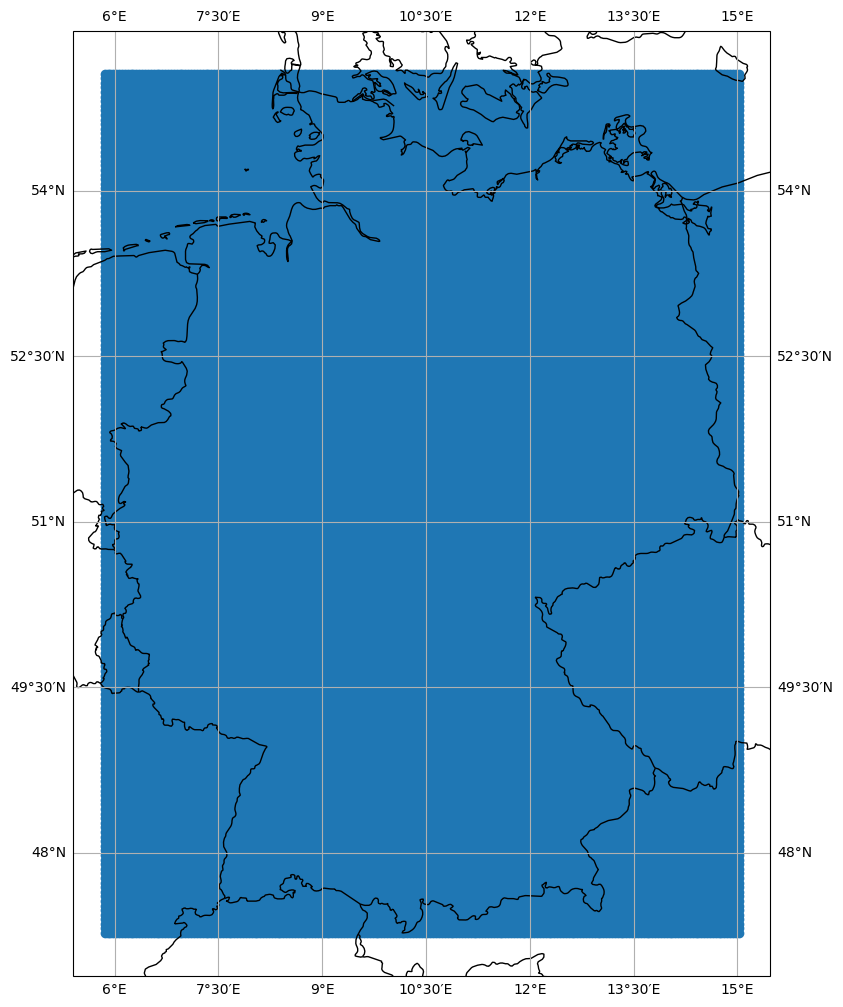

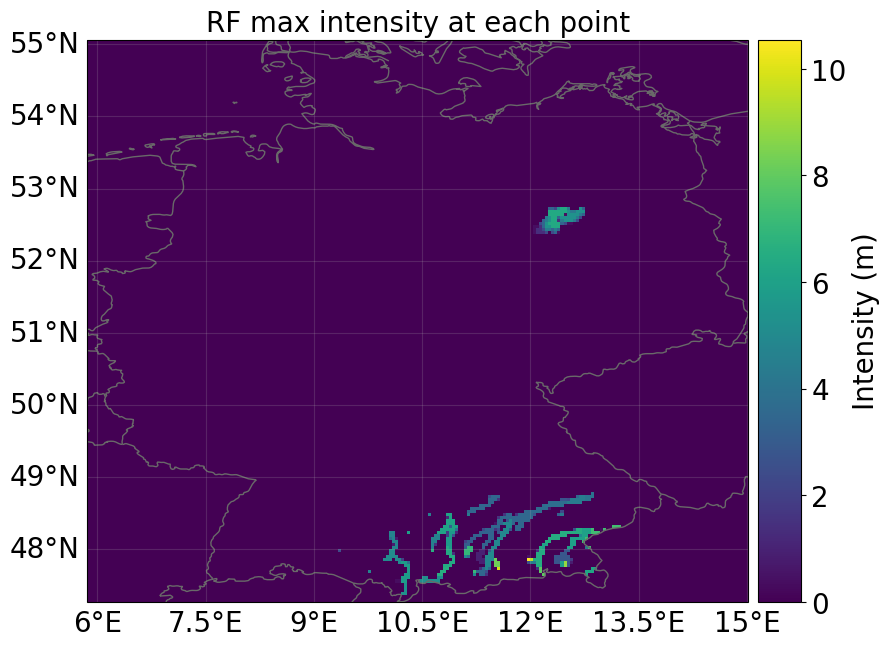

In [47]:
rf.centroids.plot()
print('resolution:', rf.centroids.get_meta()['transform'][0])
rf.plot_intensity(event=0, smooth = False);

### flooding area

Total flooded area for year 2000 in Germany:
2437074832.037465 m2
Total flooded area at first event in Germany:
2437074832.037465 m2


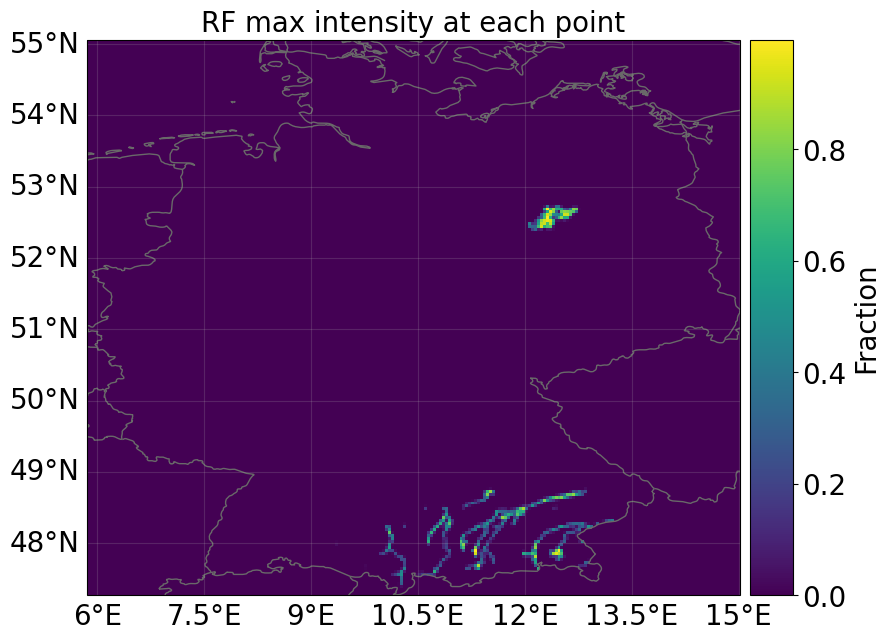

In [52]:
#setting river flood
rf_DEU = RiverFlood.from_isimip_nc(countries = ['DEU'], years=years, dph_path=HAZ_DEMO_FLDDPH, frc_path=HAZ_DEMO_FLDFRC)
rf_DEU.plot_fraction(event=0, smooth = False)
# calculating flooded area
rf_DEU.set_flooded_area()
print("Total flooded area for year " + str(years[0]) + " in Germany:")
print(str(rf_DEU.fla_annual[0]) + " m2")

print("Total flooded area at first event in Germany:")
print(str(rf_DEU.fla_event[0]) + " m2");

In [53]:
#calculate flooded area
rf_DEU.set_flooded_area(save_centr = True)
print("affected area in each affected centroid and each event:")
rf_DEU.fla_ev_centr.data

affected area in each affected centroid and each event:


array([  584715.81718127,  5053615.4298764 ,   584715.8171813 ,
         772660.21477316,  4635961.19139606,  4844788.31063623,
         877073.72577186,    62648.12847885,   793542.93642141,
         710012.09844965,   104512.31458981,  7942935.27614996,
       12980428.99754686,  8862643.59587338, 11015597.79959683,
        8151960.31900153,  8026545.76049678,  8110155.46616662,
        3428003.77254366,  2550100.30565549,  5748176.99826825,
       10743865.08815324, 10116791.51695263,   167219.69117686,
         167377.62651429,  2426975.61490299,  7866748.53141942,
       12448711.57330561, 10691246.31831924,  3807841.25590011,
         795043.75943322,  9958969.25864349, 10858623.66473204,
       10586635.08710429,  9938046.70063547,  9414992.10338908,
        4100752.00182912,    20922.20331429,  4020851.56585532,
        8628077.07460167, 12271973.68425934, 11036399.71239632,
        6135986.84212998,  5863741.76935356,  5319251.23372744,
        7936993.24828932, 12104437.71475

In [58]:
m = rf_DEU.fla_ev_centr.tocoo()

df = pd.DataFrame({
    "event":   m.row,                          # event index
    "centroid": m.col,                         # centroid index
    "lon":     rf_DEU.centroids.lon[m.col],
    "lat":     rf_DEU.centroids.lat[m.col],
    "flooded_area_m2": m.data,
})
print(df.sort_values("flooded_area_m2", ascending=False).head(10))

     event  centroid        lon        lat  flooded_area_m2
501      0     38143  11.312500  47.895833     1.438811e+07
512      0     38171  12.479167  47.895833     1.422644e+07
536      0     38391  12.437500  47.854167     1.372926e+07
523      0     38364  11.312500  47.854167     1.342879e+07
53       0     13415  12.312500  52.562500     1.301719e+07
12       0     12752  12.312500  52.687500     1.298043e+07
605      0     39249  11.354167  47.687500     1.279896e+07
558      0     38605  12.145833  47.812500     1.269923e+07
66       0     13636  12.312500  52.520833     1.263078e+07
537      0     38392  12.479167  47.854167     1.252737e+07


### Generating ISIMIP Exposure

In [61]:
# set exposure for damage calculation
from climada_petals.entity.exposures.gdp_asset import GDP2Asset
from climada_petals.util.constants import DEMO_GDP2ASSET
gdpa = GDP2Asset()
gdpa.set_countries(countries = ['CHE'], ref_year = 2000, path=DEMO_GDP2ASSET)
gdpa.gdf

,impf_RF,region_id,value,geometry
0,3.0,11.0,3.556720e+09,POINT (8.93736 45.85392)
1,3.0,11.0,2.400900e+09,POINT (8.97903 45.85392)
2,3.0,11.0,2.250146e+08,POINT (9.0207 45.85392)
3,3.0,11.0,2.939545e+08,POINT (7.10403 45.89558)
4,3.0,11.0,3.476220e+08,POINT (7.1457 45.89558)
...,...,...,...,...
2755,3.0,11.0,1.935802e+08,POINT (8.5207 47.77058)
2756,3.0,11.0,1.665060e+08,POINT (8.56236 47.77058)
2757,3.0,11.0,2.254221e+08,POINT (8.60403 47.77058)
2758,3.0,11.0,4.107628e+08,POINT (8.6457 47.77058)


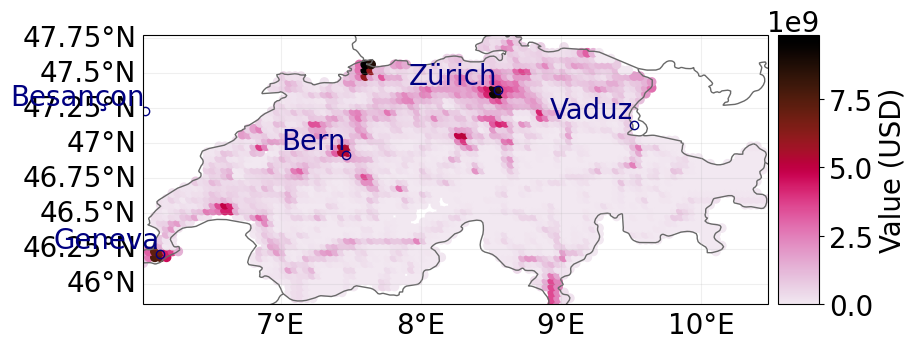

In [62]:
from matplotlib import colors
norm=colors.LogNorm(vmin=1.0e2, vmax=1.0e10)
gdpa.plot_scatter();

### Try Thailand

In [64]:
from climada_petals.hazard import river_flood
print(river_flood.DOWNLOAD_DIRECTORY)
print(river_flood.AQUEDUCT_SOURCE_LINK)

/Users/mig/climada/data/RiverFlood/Aqueduct
http://wri-projects.s3.amazonaws.com/AqueductFloodTool/download/v2/


In [73]:
from climada_petals.hazard import river_flood
river_flood.AQUEDUCT_SOURCE_LINK = "https://aqueduct.wridata.org/AqueductFloods20/"

rps = [10, 100, 1000]
hazards = {}

# baseline: historical only exists for 1980 with WATCH
hazards["hist_1980"] = RiverFlood.from_aqueduct_tif(
    scenario="historical", target_year=1980, gcm="WATCH",
    return_periods=list(rps), countries=["THA"],
)

# futures: need an RCP scenario and a climate model, not WATCH
for year in [2030, 2050, 2080]:
    hazards[f"rcp85_{year}"] = RiverFlood.from_aqueduct_tif(
        scenario="85", target_year=year, gcm="NorESM1-M",
        return_periods=list(rps), countries=["THA"],
    )

for name, h in hazards.items():
    print(name, h.intensity.max())

92.7kKB [00:36, 2.57kKB/s]                           
89.9kKB [00:32, 2.75kKB/s]                           
86.4kKB [00:45, 1.90kKB/s]                           
93.2kKB [00:52, 1.77kKB/s]                           
90.3kKB [00:46, 1.96kKB/s]                           
86.7kKB [00:43, 1.99kKB/s]                           
94.2kKB [00:33, 2.78kKB/s]                           
91.0kKB [00:40, 2.24kKB/s]                           
87.2kKB [00:31, 2.76kKB/s]                           


hist_1980 28.260891
rcp85_2030 11.989395
rcp85_2050 12.818602
rcp85_2080 13.391857


In [103]:
for name, h in hazards.items():
    t = h.centroids.get_meta()['transform']
    print(name, "resolution (deg):", t[0], "| cell height:", t[4])

hist_1980 resolution (deg): 0.00833333333333286 | cell height: -0.00833333333333286
rcp85_2030 resolution (deg): 0.00833333333333286 | cell height: -0.00833333333333286
rcp85_2050 resolution (deg): 0.00833333333333286 | cell height: -0.00833333333333286
rcp85_2080 resolution (deg): 0.00833333333333286 | cell height: -0.00833333333333286


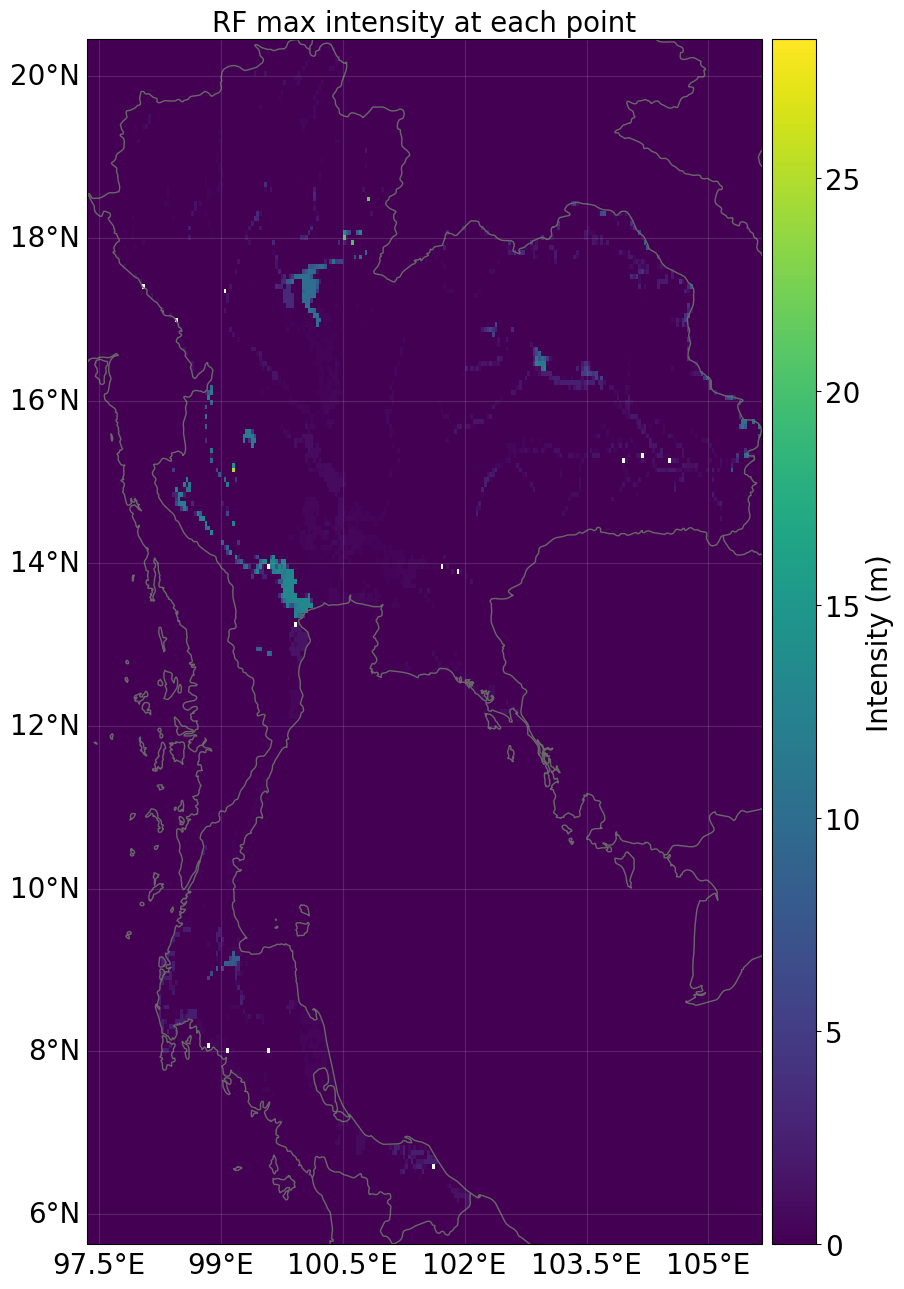

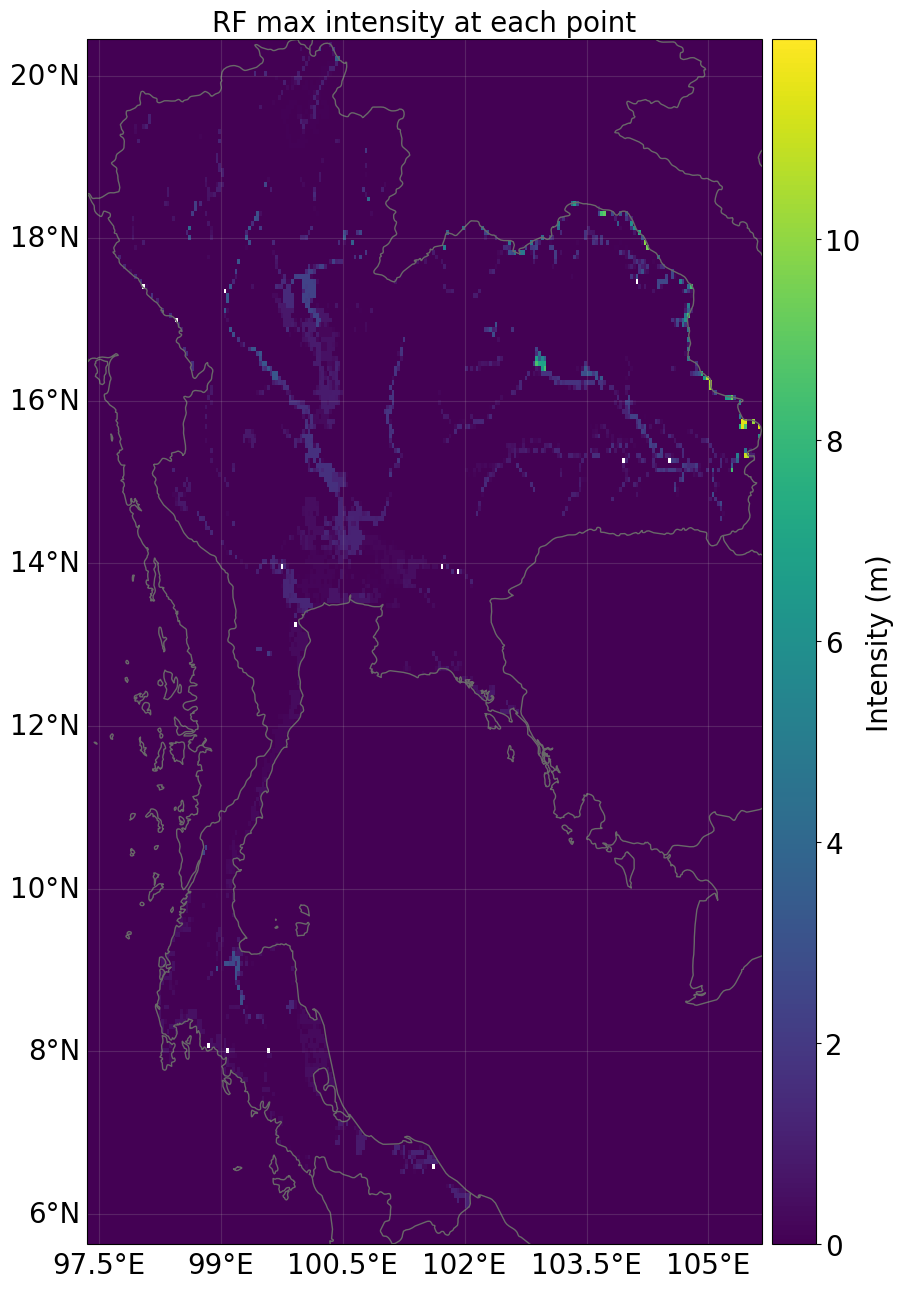

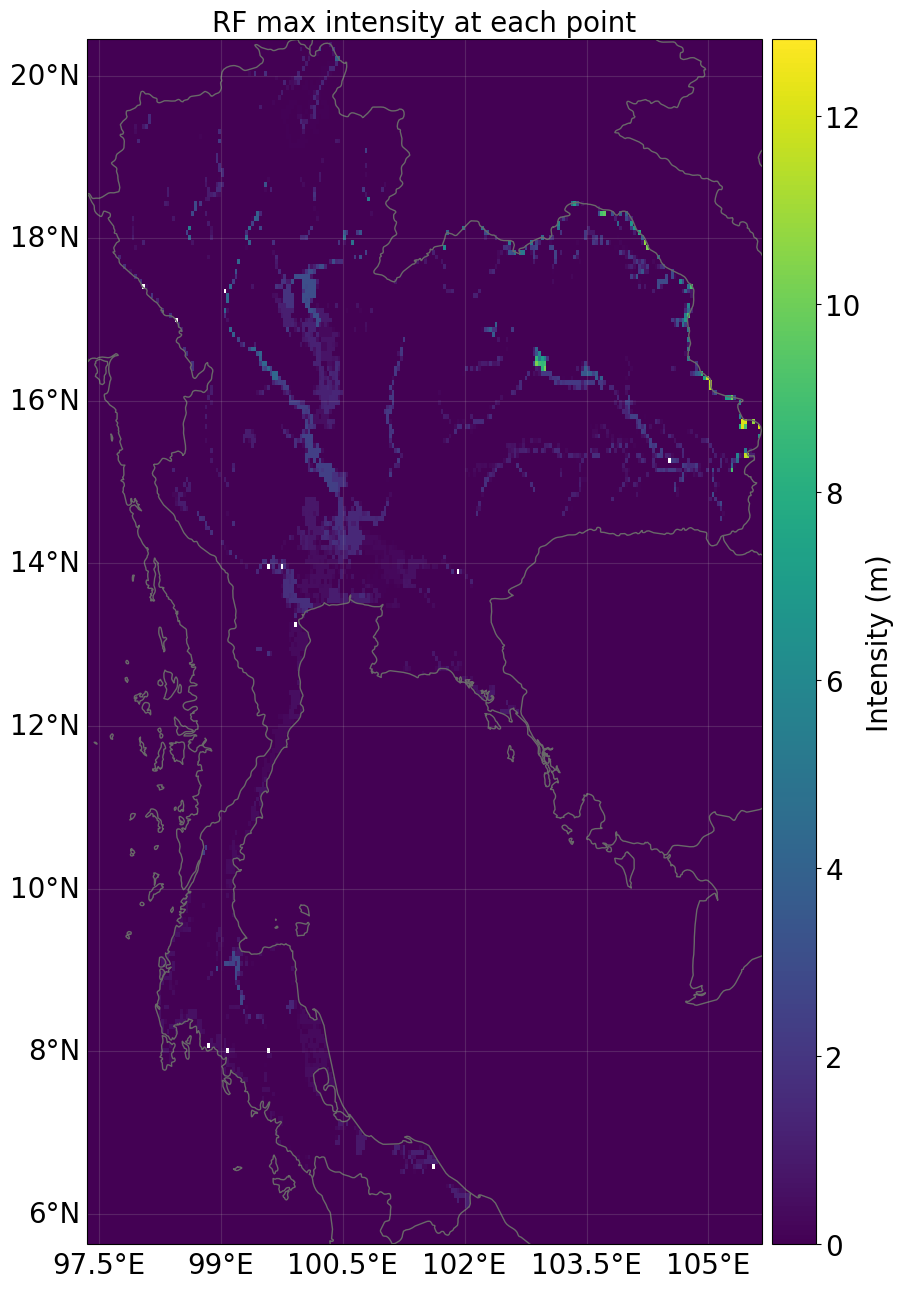

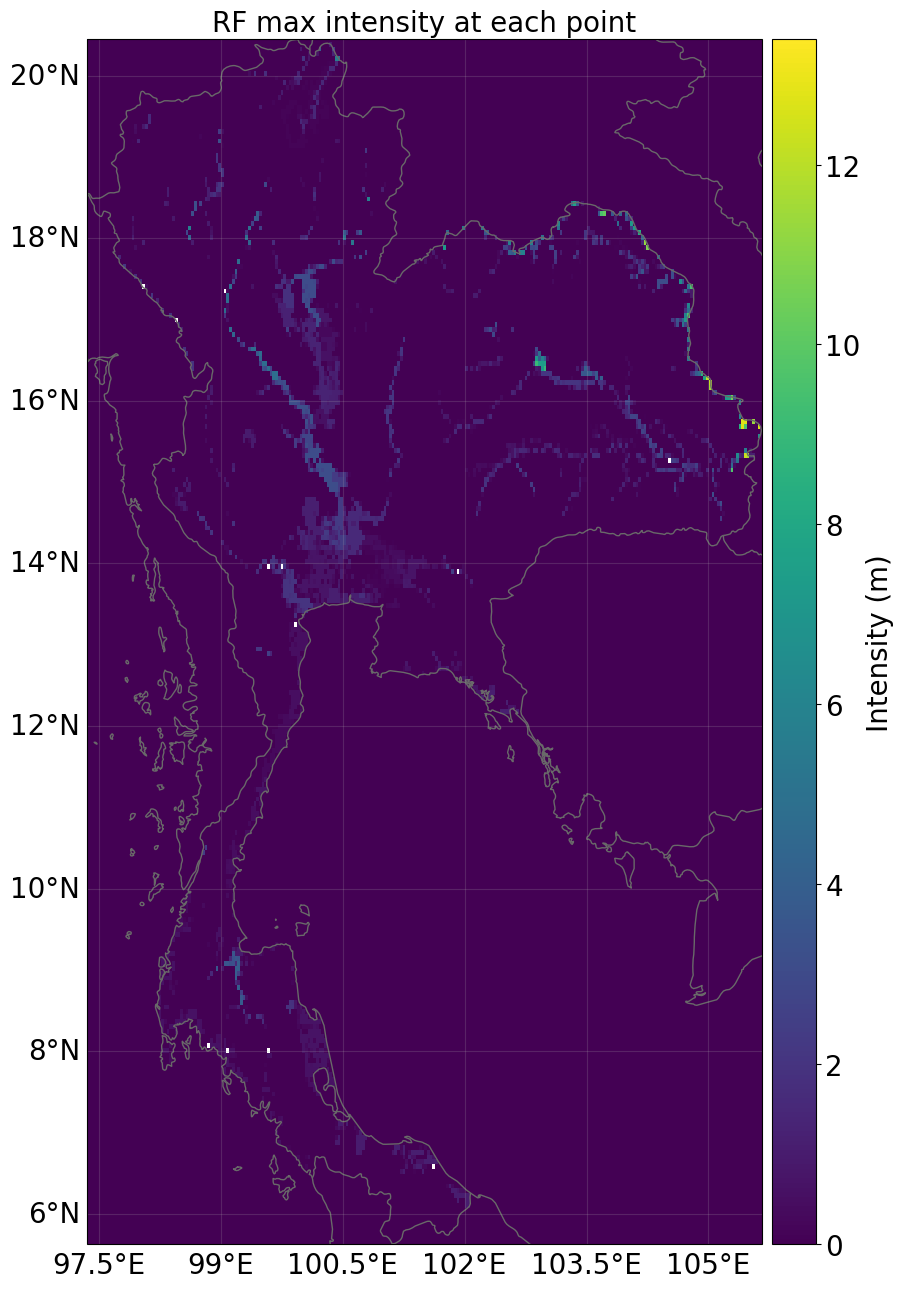

In [74]:
for i in range(len(hazards)):
    list(hazards.values())[i].plot_intensity(event=0)

### Summary table

In [80]:
base = hazards["hist_1980"]

for name, h in hazards.items():
    assert np.array_equal(h.centroids.lat, base.centroids.lat) and \
           np.array_equal(h.centroids.lon, base.centroids.lon), f"{name}: different grid"

lat, lon = base.centroids.lat, base.centroids.lon

def rp_of(event_name):
    """'1-in-100y_historical_1980' -> 100"""
    return int(event_name.split("_")[0].replace("1-in-", "").replace("y", ""))


def event_index(haz, rp):
    """Events are sorted from the largest return period down, so look the index up by name."""
    return {rp_of(n): i for i, n in enumerate(haz.event_name)}[rp]


def depth(haz, rp):
    """Dense flood depth (m) at every centroid for one return period."""
    row = haz.intensity[event_index(haz, rp)].toarray().ravel()
    return np.where(np.isfinite(row), row, 0.0)

# approximate cell area in km2 from the grid spacing (grid is regular lat/lon)
dlon = np.median(np.diff(np.unique(np.round(lon, 6))))
dlat = np.median(np.diff(np.unique(np.round(lat, 6))))
cell_km2 = (dlat * 111.32) * (dlon * 111.32 * np.cos(np.radians(lat)))
print(f"grid spacing: {dlon:.4f} deg lon x {dlat:.4f} deg lat, {len(lat)} cells")

rows = []
for name, h in hazards.items():
    for rp in sorted(rps):
        d = depth(h, rp)
        wet = d > 0
        rows.append({
            "scenario": name,
            "return_period": rp,
            "max_depth_m": d.max(),
            "mean_depth_flooded_m": d[wet].mean() if wet.any() else 0.0,
            "flooded_cells": int(wet.sum()),
            "flooded_area_km2": cell_km2[wet].sum(),
            "share_of_area_%": 100 * cell_km2[wet].sum() / cell_km2.sum(),
        })
summary = pd.DataFrame(rows)
print(summary.round(2).to_string(index=False))

grid spacing: 0.0083 deg lon x 0.0083 deg lat, 1773663 cells
  scenario  return_period  max_depth_m  mean_depth_flooded_m  flooded_cells  flooded_area_km2  share_of_area_%
 hist_1980             10     6.390000                  0.33          61784          51433.65             3.47
 hist_1980            100    18.360001                  1.16          67620          56276.71             3.80
 hist_1980           1000    28.260000                  1.92          72239          60112.82             4.05
rcp85_2030             10     6.740000                  0.36          62735          52217.97             3.52
rcp85_2030            100     9.870000                  0.71          67768          56387.33             3.80
rcp85_2030           1000    11.990000                  1.05          72049          59936.03             4.04
rcp85_2050             10     7.440000                  0.47          64627          53785.36             3.63
rcp85_2050            100    10.670000             

### Maps

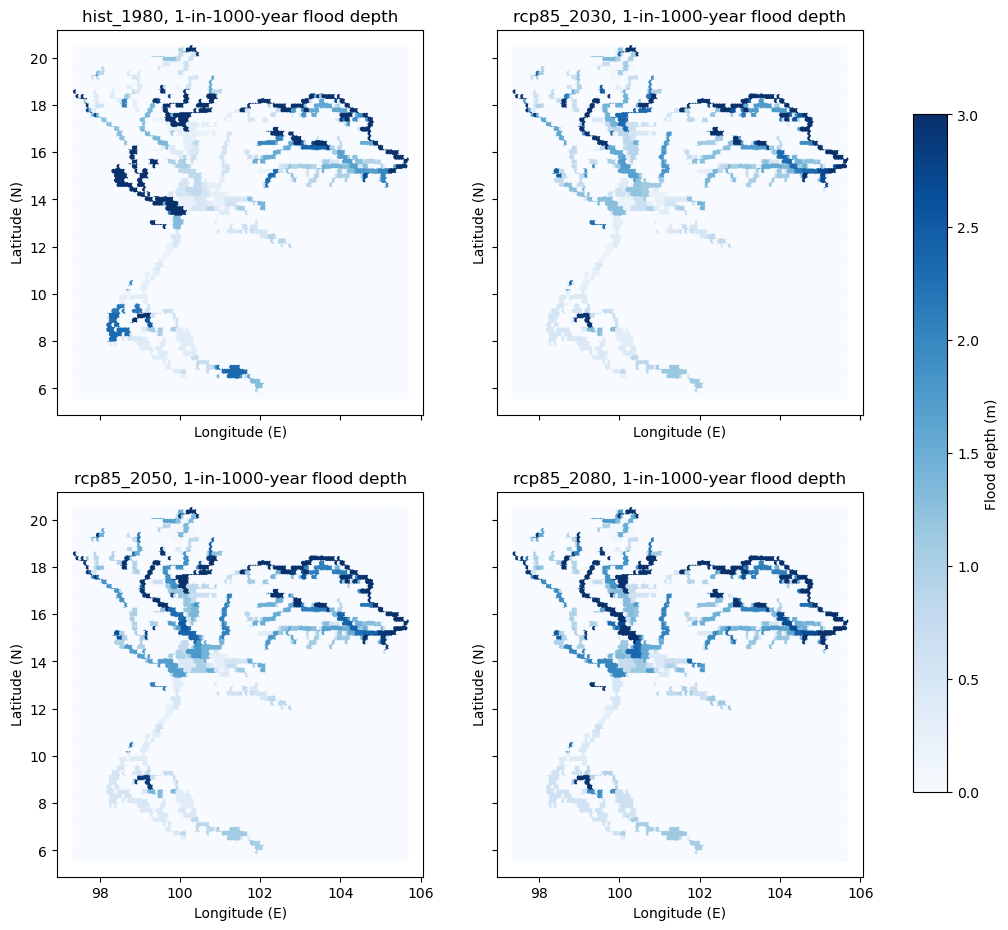

In [83]:
RP_MAP = 1000
VMAX = 3.0   # colour scale limit in metres, adjust to taste

fig, axes = plt.subplots(2, 2, figsize=(13, 11), sharex=True, sharey=True)
for ax, (name, h) in zip(axes.ravel(), hazards.items()):
    hb = ax.hexbin(lon, lat, C=depth(h, RP_MAP), gridsize=130,
                   reduce_C_function=np.max, vmin=0, vmax=VMAX, cmap="Blues")
    ax.set_title(f"{name}, 1-in-{RP_MAP}-year flood depth")
    ax.set_xlabel("Longitude (E)")
    ax.set_ylabel("Latitude (N)")
fig.colorbar(hb, ax=axes, label="Flood depth (m)", shrink=0.8)
plt.show()

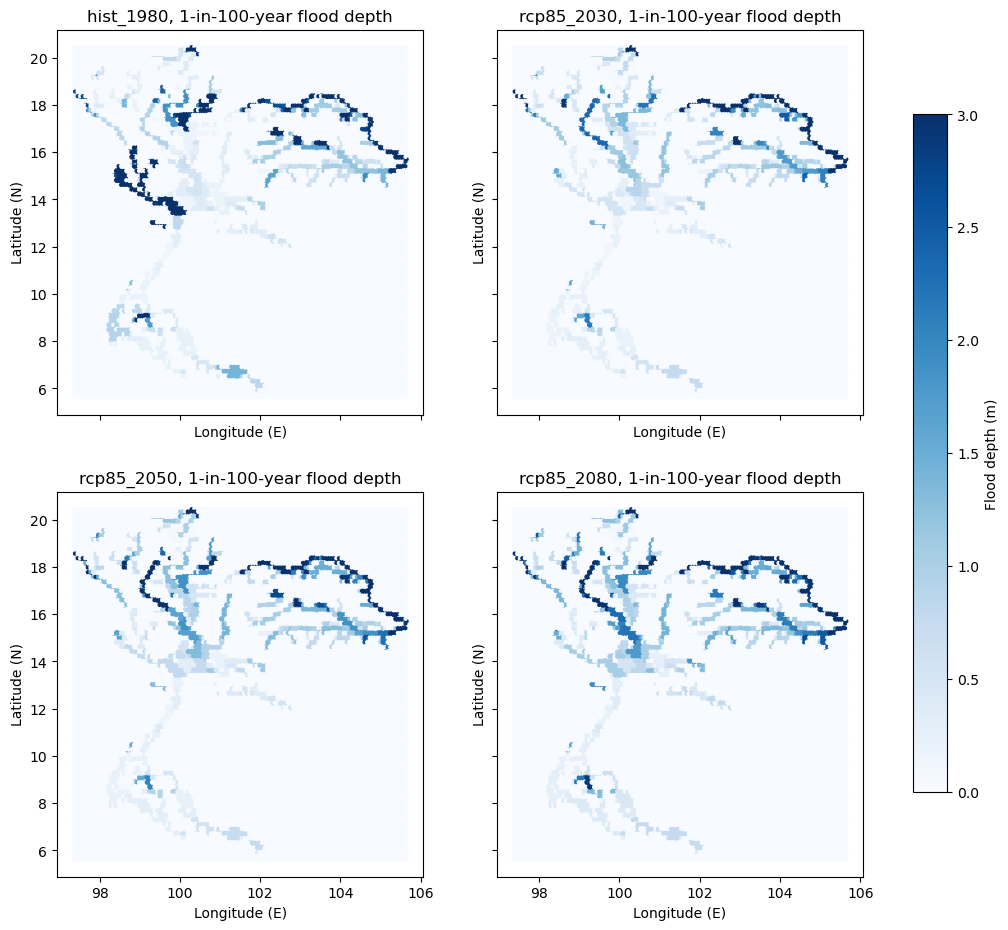

In [81]:
RP_MAP = 100
VMAX = 3.0   # colour scale limit in metres, adjust to taste

fig, axes = plt.subplots(2, 2, figsize=(13, 11), sharex=True, sharey=True)
for ax, (name, h) in zip(axes.ravel(), hazards.items()):
    hb = ax.hexbin(lon, lat, C=depth(h, RP_MAP), gridsize=130,
                   reduce_C_function=np.max, vmin=0, vmax=VMAX, cmap="Blues")
    ax.set_title(f"{name}, 1-in-{RP_MAP}-year flood depth")
    ax.set_xlabel("Longitude (E)")
    ax.set_ylabel("Latitude (N)")
fig.colorbar(hb, ax=axes, label="Flood depth (m)", shrink=0.8)
plt.show()


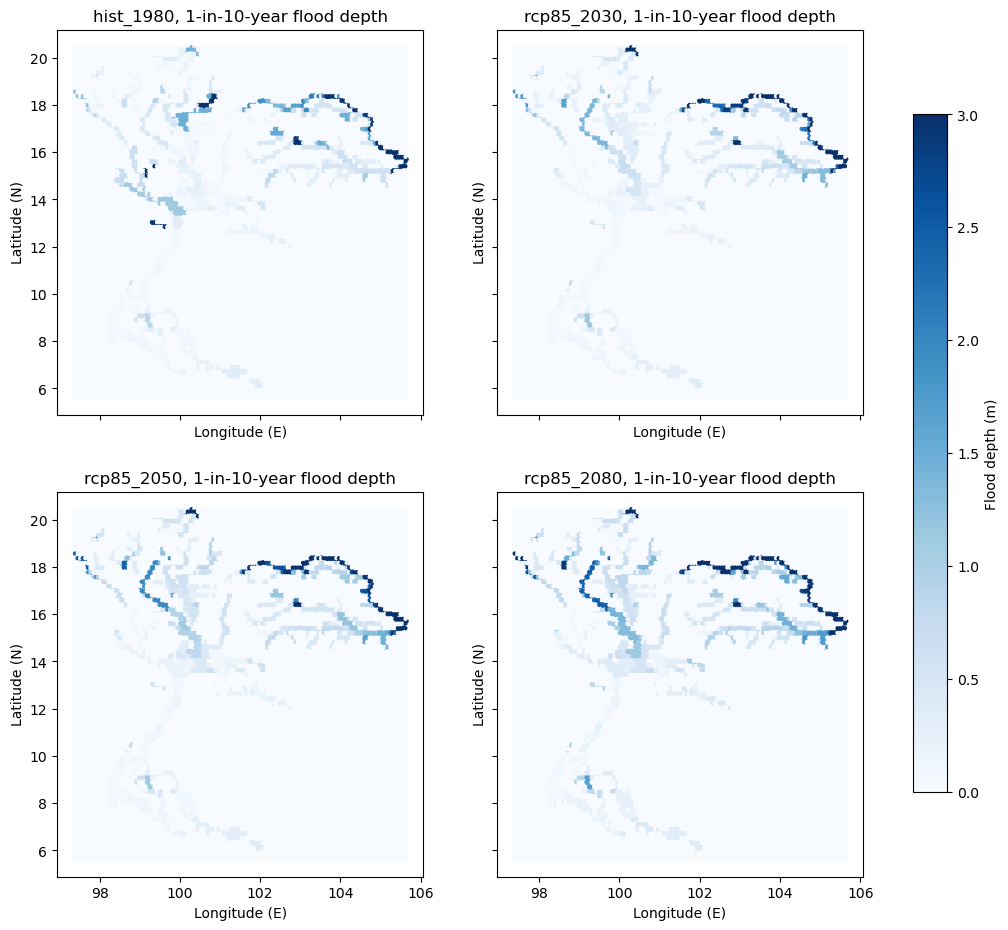

In [82]:
RP_MAP = 10
VMAX = 3.0   # colour scale limit in metres, adjust to taste

fig, axes = plt.subplots(2, 2, figsize=(13, 11), sharex=True, sharey=True)
for ax, (name, h) in zip(axes.ravel(), hazards.items()):
    hb = ax.hexbin(lon, lat, C=depth(h, RP_MAP), gridsize=130,
                   reduce_C_function=np.max, vmin=0, vmax=VMAX, cmap="Blues")
    ax.set_title(f"{name}, 1-in-{RP_MAP}-year flood depth")
    ax.set_xlabel("Longitude (E)")
    ax.set_ylabel("Latitude (N)")
fig.colorbar(hb, ax=axes, label="Flood depth (m)", shrink=0.8)
plt.show()

### Flooded area against return period

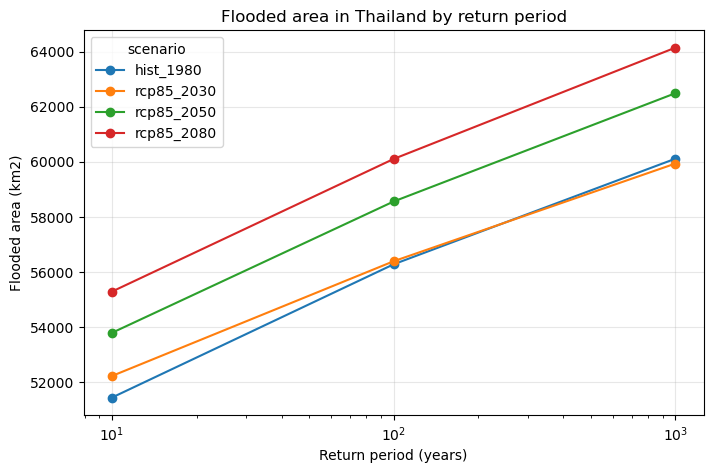

In [84]:
pivot = summary.pivot(index="return_period", columns="scenario", values="flooded_area_km2")
ax = pivot[list(hazards)].plot(marker="o", figsize=(8, 5), logx=True)
ax.set_xlabel("Return period (years)")
ax.set_ylabel("Flooded area (km2)")
ax.set_title("Flooded area in Thailand by return period")
ax.grid(alpha=0.3)
plt.show()

### Change versus baseline

Change in flooded area vs hist_1980 (%):
scenario       rcp85_2030  rcp85_2050  rcp85_2080
return_period                                    
10                    1.5         4.6         7.5
100                   0.2         4.1         6.8
1000                 -0.3         4.0         6.7


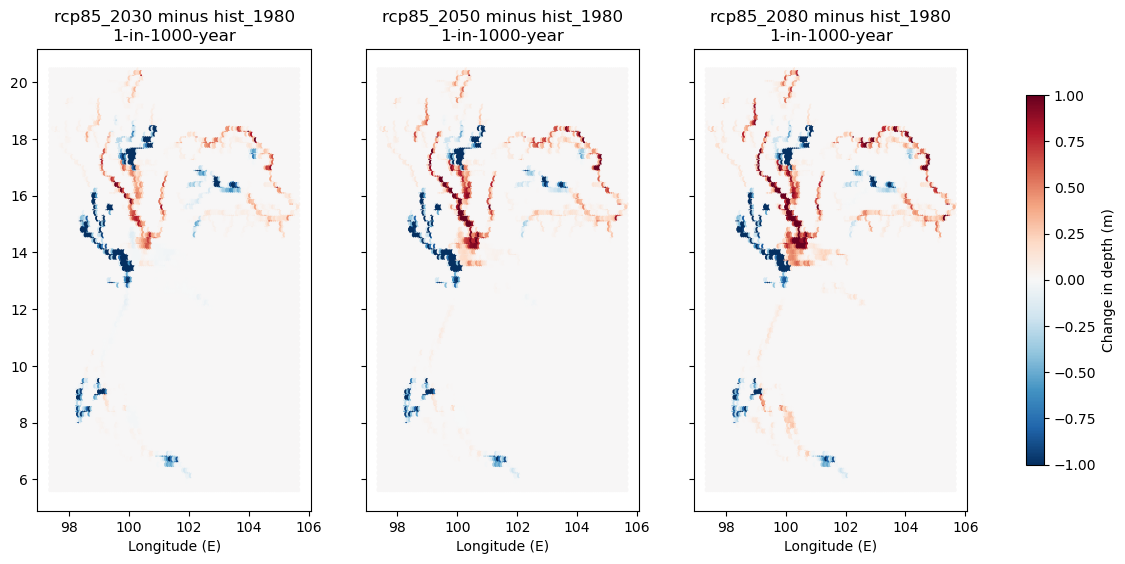

In [85]:
fut = [n for n in hazards if n != "hist_1980"]
pct = (pivot[fut].sub(pivot["hist_1980"], axis=0)).div(pivot["hist_1980"], axis=0) * 100
print("Change in flooded area vs hist_1980 (%):")
print(pct.round(1))

fig, axes = plt.subplots(1, len(fut), figsize=(5 * len(fut), 6), sharex=True, sharey=True)
for ax, name in zip(np.atleast_1d(axes), fut):
    delta = depth(hazards[name], RP_MAP) - depth(base, RP_MAP)
    hb = ax.hexbin(lon, lat, C=delta, gridsize=130, reduce_C_function=np.mean,
                   vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_title(f"{name} minus hist_1980\n1-in-{RP_MAP}-year")
    ax.set_xlabel("Longitude (E)")
fig.colorbar(hb, ax=axes, label="Change in depth (m)", shrink=0.8)
plt.show()

### Place lookups

In [96]:
places = {"Bangkok": (13.75, 100.50), "Chiang Mai": (18.79, 98.98), "Hat Yai": (7.01, 100.47)}
radius_km = 10

out = []
for place, (plat, plon) in places.items():
    dist = np.hypot((lat - plat) * 111.32,
                    (lon - plon) * 111.32 * np.cos(np.radians(plat)))
    near = dist <= radius_km
    if not near.any():
        print(f"no cells within {radius_km} km of {place}; nearest is {dist.min():.1f} km")
        continue
    for name, h in hazards.items():
        for rp in sorted(rps):
            out.append({"place": place, "scenario": name, "return_period": rp,
                        "depth_m": depth(h, rp)[near].max()})

places_df = pd.DataFrame(out).pivot_table(index=["place", "return_period"],
                                          columns="scenario", values="depth_m")
print(places_df[list(hazards)].round(2))

scenario                  hist_1980  rcp85_2030  rcp85_2050  rcp85_2080
place      return_period                                               
Bangkok    10                  0.16        0.25        0.42        0.52
           100                 0.35        0.46        0.74        0.83
           1000                0.52        0.65        1.02        1.12
Chiang Mai 10                  0.12        0.32        0.52        0.79
           100                 0.26        0.59        1.00        1.45
           1000                0.41        0.95        1.51        2.04
Hat Yai    10                  0.22        0.29        0.30        0.42
           100                 0.48        0.57        0.58        0.74
           1000                0.73        0.84        0.85        1.04


### Turn depth into economic losses

In [100]:

RUN_IMPACT = True
ASIA_IMPF_ID = 2      # CHECK against the ids printed below

if RUN_IMPACT:
    from climada.entity import LitPop
    from climada.engine import ImpactCalc
    from climada_petals.entity.impact_funcs.river_flood import flood_imp_func_set

    exp = LitPop.from_nightlight_intensity(countries=["THA"])
    impf_set = flood_imp_func_set()
    print("impact function ids:", impf_set.get_ids())
    exp.gdf["impf_RF"] = ASIA_IMPF_ID          # column name = "impf_" + hazard type code

    results = {}
    for name, h in hazards.items():
        imp = ImpactCalc(exp, impf_set, h).impact()
        results[name] = imp.aai_agg
        print(f"{name}: expected annual impact = {imp.aai_agg:,.0f}")

FileNotFoundError: The file /Users/mig/climada/data/gpw-v4-population-count-rev11_2020_30_sec_tif/gpw_v4_population_count_rev11_2020_30_sec.tif could not be found. Please download the file first or choose a different folder. The data can be downloaded from http://sedac.ciesin.columbia.edu/data/collection/gpw-v4/sets/browse, e.g., http://sedac.ciesin.columbia.edu/downloads/data/gpw-v4/gpw-v4-population-count-rev11/gpw-v4-population-count-rev11_2020_30_sec_tif.zip (Free NASA Earthdata login required).